# Blinkit Grocery Sales Analysis
## 03 – Exploratory Data Analysis (EDA)
### One command / operation per Jupyter code cell

**Purpose:** Explore the cleaned Blinkit grocery dataset and answer business questions using Python.

**Input file:** `Dataset/blinkit_sales_cleaned.csv`

**How to use:** Run the notebook from top to bottom. Each code cell is intentionally kept focused on one command or one small operation so you can execute it, inspect the output, and understand what it does.

> This notebook does not modify the source dataset. It creates charts and summary tables for analysis.

## 1. Import libraries

Import library's for data analysis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
pd.set_option('display.max_columns', None) #Set Pandas to display all columns.
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')  #Set the display format for floating-point values.
sns.set_theme(style='whitegrid')  # Set a consistent chart theme.

## 2. Load the cleaned dataset

Set the relative path to the cleaned CSV. This assumes the notebook is inside the `Notebooks` folder.

In [3]:
DATA_PATH = Path('../Dataset/blinkit_sales_cleaned.csv')
DATA_PATH.exists()
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH.resolve()}. "
        "Update DATA_PATH to the location of blinkit_sales_cleaned.csv"
    )

df = pd.read_csv(DATA_PATH)
sns.set_theme(style='whitegrid')

In [4]:
df.head()

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.10,15.10,145.48,5.00
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.01,11.80,115.35,5.00
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.03,13.85,165.02,5.00
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.04,12.15,126.50,5.00
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.03,19.60,55.16,5.00


Display the number of rows and columns.

In [5]:
df.shape

(8523, 12)

## 3. Validate the dataset

Display all column names.

In [6]:
df.columns

Index(['Item Fat Content', ' Item Identifier', ' Item Type            ',
       ' Outlet Establishment Year', ' Outlet Identifier',
       ' Outlet Location Type', ' Outlet Size', ' Outlet Type      ',
       ' Item Visibility', ' Item Weight', ' Sales   ', ' Rating'],
      dtype='str')

Display the data types and non-null counts.

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Item Fat Content            8523 non-null   str    
 1    Item Identifier            8523 non-null   str    
 2    Item Type                  8523 non-null   str    
 3    Outlet Establishment Year  8523 non-null   int64  
 4    Outlet Identifier          8523 non-null   str    
 5    Outlet Location Type       8523 non-null   str    
 6    Outlet Size                8523 non-null   str    
 7    Outlet Type                8523 non-null   str    
 8    Item Visibility            8523 non-null   float64
 9    Item Weight                8523 non-null   float64
 10   Sales                      8523 non-null   float64
 11   Rating                     8523 non-null   float64
dtypes: float64(4), int64(1), str(7)
memory usage: 799.2 KB


Count missing values in each column.

In [8]:
df.isnull().sum()

Item Fat Content              0
 Item Identifier              0
 Item Type                    0
 Outlet Establishment Year    0
 Outlet Identifier            0
 Outlet Location Type         0
 Outlet Size                  0
 Outlet Type                  0
 Item Visibility              0
 Item Weight                  0
 Sales                        0
 Rating                       0
dtype: int64

Count exact duplicate rows.

In [9]:
df.duplicated().sum()

np.int64(0)

Display the numerical summary.

In [10]:
df.describe()

,Outlet Establishment Year,Item Visibility,Item Weight,Sales,Rating
count,"8,523.00","8,523.00","8,523.00","8,523.00","8,523.00"
mean,"2,016.45",0.07,12.88,140.99,3.97
std,3.19,0.05,4.65,62.28,0.61
min,"2,011.00",0.00,4.55,31.29,1.00
25%,"2,014.00",0.03,8.79,93.83,4.00
50%,"2,016.00",0.05,12.65,143.01,4.00
75%,"2,018.00",0.09,16.85,185.64,4.20
max,"2,022.00",0.33,21.35,266.89,5.00


Display the categorical summary.

In [14]:
df.describe(include='object').T

C:\Users\Sripada Pavankumar\AppData\Local\Temp\ipykernel_14084\1760094569.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object').T


,count,unique,top,freq
Item Fat Content,8523,2,Low Fat,5517
Item Identifier,8523,1559,FDW13,10
Item Type,8523,16,Fruits and Vegetables,1232
Outlet Identifier,8523,10,OUT027,935
Outlet Location Type,8523,3,Tier 3,3350
Outlet Size,8523,3,Medium,3631
Outlet Type,8523,4,Supermarket Type1,5577


Check that the required fields are available.

In [15]:
required_columns = [
    'Item Identifier', 'Item Fat Content', 'Item Type',
    'Outlet Establishment Year', 'Outlet Identifier',
    'Outlet Location Type', 'Outlet Size', 'Outlet Type',
    'Item Visibility', 'Item Weight', 'Sales', 'Rating'
]
missing_columns = [column for column in required_columns if column not in df.columns]
missing_columns

['Item Identifier',
 'Item Type',
 'Outlet Establishment Year',
 'Outlet Identifier',
 'Outlet Location Type',
 'Outlet Size',
 'Outlet Type',
 'Item Visibility',
 'Item Weight',
 'Sales',
 'Rating']

## 4. Business KPIs

Calculate total sales.

In [19]:
sales_column = next(
    (column for column in df.columns if column.strip().lower() in {'sales', 'item outlet sales', 'item_outlet_sales'}),
    None
)

if sales_column is None:
    raise KeyError(f"Sales column not found. Available columns: {list(df.columns)}")

if sales_column != 'Sales':
    df = df.rename(columns={sales_column: 'Sales'})

total_sales = df['Sales'].sum()

In [22]:
print(total_sales)

1201681.4928000001


Calculate average sales per dataset record.

In [24]:
average_sales_per_record = df['Sales'].mean()
print(average_sales_per_record)

140.99278338613166


Count the number of records.

In [25]:
record_count = len(df)
print(record_count)

8523


Count unique products.

In [27]:
# Clean whitespace from all column names before accessing them.
df.columns = df.columns.str.strip()

unique_products = df['Item Identifier'].nunique()
print(unique_products)
print(unique_products)

1559
1559


Count unique outlets.

In [30]:
unique_outlets = df['Outlet Identifier'].nunique()
print(unique_outlets)

10


Calculate average rating.

In [31]:
average_rating = df['Rating'].mean()
print(average_rating)

3.965857092573038


Create a KPI summary table.

In [32]:
kpi_table = pd.DataFrame({
    'Metric': [
        'Total Sales',
        'Average Sales per Record',
        'Number of Records',
        'Unique Products',
        'Unique Outlets',
        'Average Rating'
    ],
    'Value': [
        total_sales,
        average_sales_per_record,
        record_count,
        unique_products,
        unique_outlets,
        average_rating
    ]
})

In [33]:
kpi_table

,Metric,Value
0,Total Sales,"1,201,681.49"
1,Average Sales per Record,140.99
2,Number of Records,"8,523.00"
3,Unique Products,"1,559.00"
4,Unique Outlets,10.00
5,Average Rating,3.97


## 5. Sales by Item Type

Group records by Item Type and calculate total sales.

In [34]:
sales_by_item_type = df.groupby('Item Type', as_index=False)['Sales'].sum()

Rename the sales column.

In [35]:
sales_by_item_type = sales_by_item_type.rename(columns={'Sales': 'Total Sales'})

Sort item types from highest to lowest total sales.

In [58]:
sales_by_item_type = sales_by_item_type.sort_values('Total Sales', ascending=False)
sales_by_item_type

,Item Type,Total Sales,Sales Contribution (%)
6,Fruits and Vegetables,"178,124.08",14.82
13,Snack Foods,"175,433.92",14.60
9,Household,"135,976.53",11.32
5,Frozen Foods,"118,558.88",9.87
4,Dairy,"101,276.46",8.43
3,Canned,"90,706.73",7.55
0,Baking Goods,"81,894.74",6.82
8,Health and Hygiene,"68,025.84",5.66
10,Meat,"59,449.86",4.95
14,Soft Drinks,"58,514.17",4.87


Calculate each item's percentage contribution to total sales.

In [38]:
sales_by_item_type['Sales Contribution (%)'] = sales_by_item_type['Total Sales'] / total_sales * 100

In [39]:
sales_by_item_type

,Item Type,Total Sales,Sales Contribution (%)
6,Fruits and Vegetables,"178,124.08",14.82
13,Snack Foods,"175,433.92",14.60
9,Household,"135,976.53",11.32
5,Frozen Foods,"118,558.88",9.87
4,Dairy,"101,276.46",8.43
3,Canned,"90,706.73",7.55
0,Baking Goods,"81,894.74",6.82
8,Health and Hygiene,"68,025.84",5.66
10,Meat,"59,449.86",4.95
14,Soft Drinks,"58,514.17",4.87


Plot total sales by item type.

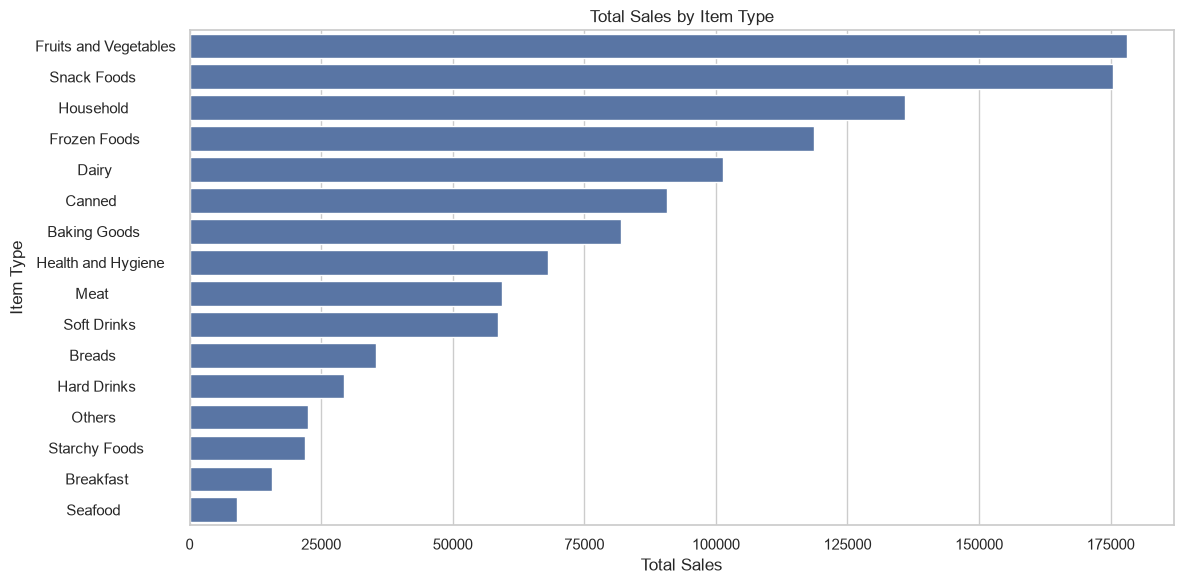

In [40]:
plt.figure(figsize=(12, 6))
sns.barplot(data=sales_by_item_type, x='Total Sales', y='Item Type')
plt.title('Total Sales by Item Type')
plt.xlabel('Total Sales')
plt.ylabel('Item Type')
plt.tight_layout()
plt.show()

## 6. Sales by Outlet Type

Calculate total sales by outlet type.

In [41]:
sales_by_outlet_type = df.groupby('Outlet Type', as_index=False)['Sales'].sum()

Rename the sales column.

In [42]:
sales_by_outlet_type = sales_by_outlet_type.rename(columns={'Sales': 'Total Sales'})

Sort outlet types by total sales.

In [57]:
sales_by_outlet_type = sales_by_outlet_type.sort_values('Total Sales', ascending=False)
sales_by_outlet_type

,Outlet Type,Total Sales
1,Supermarket Type1,"787,549.89"
0,Grocery Store,"151,939.15"
2,Supermarket Type2,"131,477.78"
3,Supermarket Type3,"130,714.67"


Plot total sales by outlet type.

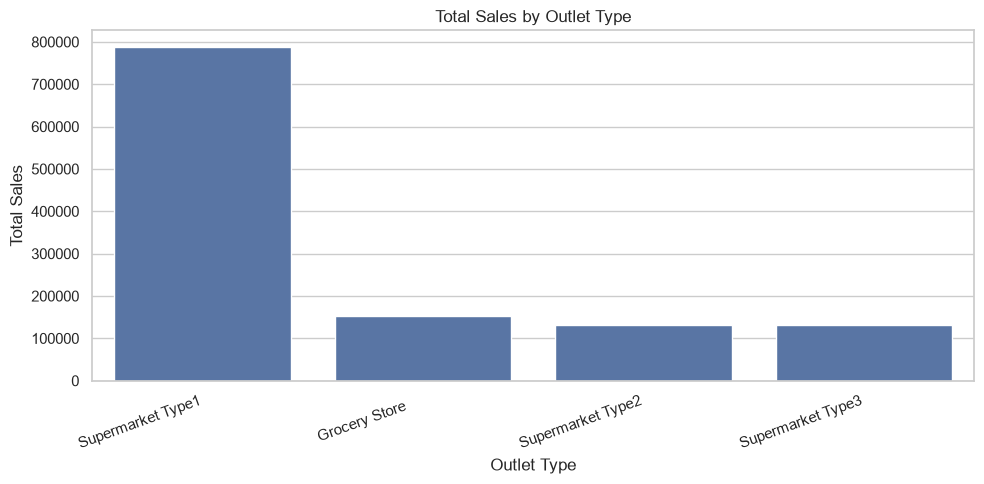

In [45]:
plt.figure(figsize=(10, 5))
sns.barplot(data=sales_by_outlet_type, x='Outlet Type', y='Total Sales')
plt.title('Total Sales by Outlet Type')
plt.xlabel('Outlet Type')
plt.ylabel('Total Sales')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

## 7. Sales by Outlet Location Type

Calculate total sales by location tier.

In [46]:
sales_by_location = df.groupby('Outlet Location Type', as_index=False)['Sales'].sum()

Sort location tiers by total sales.

In [50]:
sales_by_location = sales_by_location.sort_values('Sales', ascending=False)
sales_by_location

,Outlet Location Type,Sales
2,Tier 3,"472,133.03"
1,Tier 2,"393,150.65"
0,Tier 1,"336,397.81"


Plot total sales by location tier.

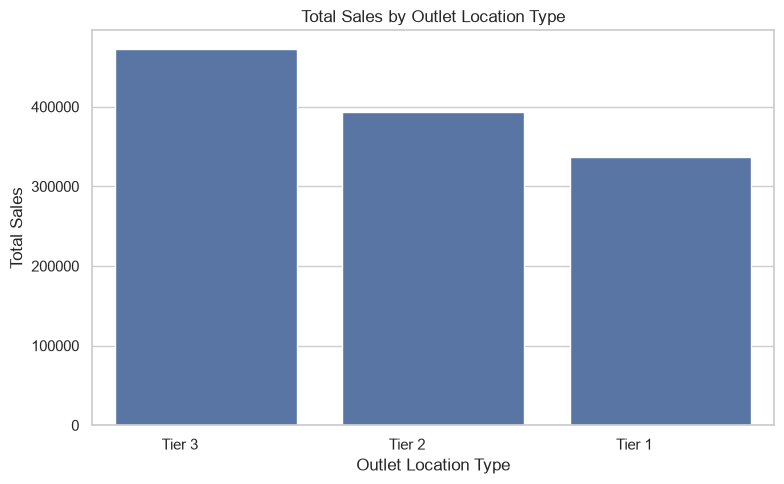

In [51]:
plt.figure(figsize=(8, 5))
sns.barplot(data=sales_by_location, x='Outlet Location Type', y='Sales')
plt.title('Total Sales by Outlet Location Type')
plt.xlabel('Outlet Location Type')
plt.ylabel('Total Sales')
plt.tight_layout()
plt.show()

## 8. Sales by Outlet Size

Calculate total sales by outlet size.

In [52]:
sales_by_outlet_size = df.groupby('Outlet Size', as_index=False)['Sales'].sum()

Sort outlet sizes by total sales.

In [56]:
sales_by_outlet_size = sales_by_outlet_size.sort_values('Sales', ascending=False)
sales_by_outlet_size

,Outlet Size,Sales
1,Medium,"507,895.74"
2,Small,"444,794.17"
0,High,"248,991.59"


Plot total sales by outlet size.

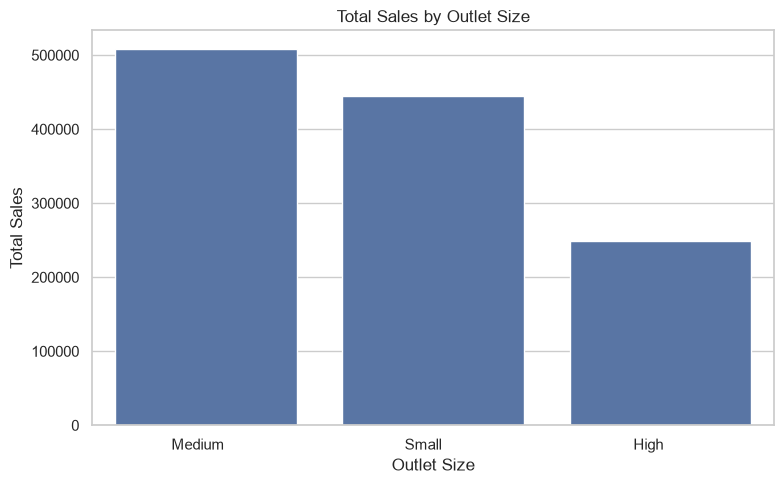

In [55]:
plt.figure(figsize=(8, 5))
sns.barplot(data=sales_by_outlet_size, x='Outlet Size', y='Sales')
plt.title('Total Sales by Outlet Size')
plt.xlabel('Outlet Size')
plt.ylabel('Total Sales')
plt.tight_layout()
plt.show()

## 9. Sales by Item Fat Content

Calculate total sales by fat-content category.

In [ ]:
sales_by_fat_content = df.groupby('Item Fat Content', as_index=False)['Sales'].sum()

Sort the categories by total sales.

In [ ]:
sales_by_fat_content = (
    df.groupby('Item Fat Content', as_index=False)['Sales']
      .sum()
      .sort_values('Sales', ascending=False)
)
sales_by_fat_content
sales_by_fat_content

NameError: name 'sales_by_fat_content' is not defined

Display the summary.

In [ ]:
sales_by_fat_content

Plot total sales by fat-content category.

In [ ]:
plt.figure(figsize=(7, 5))
sns.barplot(data=sales_by_fat_content, x='Item Fat Content', y='Sales')
plt.title('Total Sales by Item Fat Content')
plt.xlabel('Item Fat Content')
plt.ylabel('Total Sales')
plt.tight_layout()
plt.show()

## 10. Sales by Outlet Establishment Year

Calculate total sales for each outlet establishment year.

In [ ]:
sales_by_establishment = df.groupby('Outlet Establishment Year', as_index=False)['Sales'].sum()

Sort the years in ascending order.

In [ ]:
sales_by_establishment = sales_by_establishment.sort_values('Outlet Establishment Year')

Display the summary.

In [ ]:
sales_by_establishment

Plot total sales by outlet establishment year.

In [ ]:
plt.figure(figsize=(10, 5))
sns.lineplot(data=sales_by_establishment, x='Outlet Establishment Year', y='Sales', marker='o')
plt.title('Total Sales by Outlet Establishment Year')
plt.xlabel('Outlet Establishment Year')
plt.ylabel('Total Sales')
plt.tight_layout()
plt.show()

> Interpretation note: Establishment year is not the year of each transaction. This chart compares outlets by their establishment year; it is not a time-series sales trend.

## 11. Item Visibility analysis

Display descriptive statistics for item visibility.

In [ ]:
df['Item Visibility'].describe()

Count records where item visibility is zero.

In [ ]:
(df['Item Visibility'] == 0).sum()

Plot the distribution of item visibility.

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Item Visibility', kde=True)
plt.title('Distribution of Item Visibility')
plt.xlabel('Item Visibility')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

Plot item visibility against sales.

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Item Visibility', y='Sales', alpha=0.35)
plt.title('Item Visibility vs Sales')
plt.xlabel('Item Visibility')
plt.ylabel('Sales')
plt.tight_layout()
plt.show()

Calculate the correlation between item visibility and sales.

In [ ]:
df['Item Visibility'].corr(df['Sales'])

## 12. Item Weight analysis

Display descriptive statistics for item weight.

In [ ]:
df['Item Weight'].describe()

Plot item weight against sales.

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Item Weight', y='Sales', alpha=0.4)
plt.title('Item Weight vs Sales')
plt.xlabel('Item Weight')
plt.ylabel('Sales')
plt.tight_layout()
plt.show()

Calculate the correlation between item weight and sales.

In [ ]:
df['Item Weight'].corr(df['Sales'])

> Item Weight values were imputed during cleaning. Treat this relationship as exploratory because some weights are estimates.

## 13. Rating analysis

Display the distribution of ratings.

In [ ]:
df['Rating'].value_counts().sort_index()

Calculate the average rating.

In [ ]:
df['Rating'].mean()

Calculate the median rating.

In [ ]:
df['Rating'].median()

Plot rating frequencies.

In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Rating')
plt.title('Distribution of Ratings')
plt.xlabel('Rating')
plt.ylabel('Number of Records')
plt.tight_layout()
plt.show()

## 14. Correlation analysis

Select numerical columns and calculate their correlation matrix.

In [ ]:
numeric_corr = df.select_dtypes(include=np.number).corr()

Display the correlation matrix.

In [ ]:
numeric_corr

Visualize the correlation matrix.

In [ ]:
plt.figure(figsize=(9, 6))
sns.heatmap(numeric_corr, annot=True, fmt='.2f', cmap='Blues', linewidths=0.5)
plt.title('Correlation Matrix – Numerical Variables')
plt.tight_layout()
plt.show()

## 15. Outlet-level performance

Calculate total sales by outlet.

In [ ]:
outlet_performance = df.groupby('Outlet Identifier', as_index=False)['Sales'].sum()

Rename the sales column.

In [ ]:
outlet_performance = outlet_performance.rename(columns={'Sales': 'Total Sales'})

Sort outlets from highest to lowest total sales.

In [ ]:
outlet_performance = outlet_performance.sort_values('Total Sales', ascending=False)

Display outlet performance.

In [ ]:
outlet_performance

Plot total sales by outlet.

In [ ]:
plt.figure(figsize=(10, 5))
sns.barplot(data=outlet_performance, x='Outlet Identifier', y='Total Sales')
plt.title('Total Sales by Outlet')
plt.xlabel('Outlet Identifier')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 16. Top and bottom product categories

Display the five highest-sales categories.

In [ ]:
sales_by_item_type.head(5)

Display the five lowest-sales categories.

In [ ]:
sales_by_item_type.tail(5).sort_values('Total Sales')

## 17. Automatically identify leading categories and outlets

Find the item category with the highest total sales.

In [ ]:
top_category = sales_by_item_type.iloc[0]

In [ ]:
top_category

Find the outlet with the highest total sales.

In [ ]:
top_outlet = outlet_performance.iloc[0]

In [ ]:
top_outlet

Print the overall sales total.

In [ ]:
print(f'Total sales: {total_sales:,.2f}')

Print the average sales per record.

In [ ]:
print(f'Average sales per record: {average_sales_per_record:,.2f}')

Print the average rating.

In [ ]:
print(f'Average rating: {average_rating:.2f}')

## 18. Export summary tables to Excel

Create the Reports folder if it does not exist.

In [ ]:
REPORT_DIR = Path('../Reports')

In [ ]:
REPORT_DIR.mkdir(parents=True, exist_ok=True)

Set the Excel output path.

In [ ]:
EDA_OUTPUT = REPORT_DIR / 'blinkit_eda_summary.xlsx'

Export KPI and category summary tables to separate Excel sheets.

In [ ]:
with pd.ExcelWriter(EDA_OUTPUT, engine='openpyxl') as writer:
    kpi_table.to_excel(writer, sheet_name='KPIs', index=False)
    sales_by_item_type.to_excel(writer, sheet_name='Sales by Item Type', index=False)
    sales_by_outlet_type.to_excel(writer, sheet_name='Sales by Outlet Type', index=False)
    sales_by_location.to_excel(writer, sheet_name='Sales by Location', index=False)
    sales_by_outlet_size.to_excel(writer, sheet_name='Sales by Outlet Size', index=False)
    sales_by_fat_content.to_excel(writer, sheet_name='Sales by Fat Content', index=False)
    sales_by_establishment.to_excel(writer, sheet_name='Sales by Establishment', index=False)
    outlet_performance.to_excel(writer, sheet_name='Outlet Performance', index=False)

Display the saved report path.

In [ ]:
print(f'EDA report saved to: {EDA_OUTPUT.resolve()}')

## 19. Business insights – complete after reviewing the outputs

Write your findings in your own words, using values from the tables and charts.

1. Which item category has the highest total sales?
2. Which outlet type has the highest total sales?
3. Which location tier leads in total sales?
4. Which outlet size has the highest total sales?
5. Which fat-content category contributes more sales?
6. Is item visibility meaningfully correlated with sales?
7. Which outlet has the highest total sales?

### Limitations
- This is a historical grocery retail dataset, not verified live Blinkit operational data.
- No customer ID or transaction ID is available, so we cannot calculate unique customers or order counts.
- No cost field is available, so sales must not be described as profit.
- Outlet establishment year is not a transaction date.
- Correlation does not establish causation.
- Imputed item weights are estimates.

### Next step
Use validated EDA findings to build SQL business analysis and a Power BI dashboard.